# Student Performance Indicator

## Lifecycle of Machine Learning Project

####

* Understanding the problem statement
* Data collection
* Data checks to perform
* Exploratory data analysis
* Data pre-processing
* Model training
* Choose best model

1. Problem Statement
* This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ehnicity, Parental level of education, lunch and test preparation course

2. Data Collection
* Dataset source- kaggle
* Data consists of 8 columns and 1000 rows

2.1. Import Data and required packages
Importing pandas, numpy, matplotlib, seaborn, and warnings library


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('data/stud.csv')

In [4]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [6]:
df.shape

(1000, 8)

## 2.2 Dataset Information

####
* gender: sex of the students -> (Male/Female)
* race/ethnicity: ethnicity of students -> Group (A,B,C,D)
* Parental level of education: parent's final education -> (bachelor's degree, some college,masters degree, associate's degree, high school)
*   lunch: having lunch before test (standard or free/reduced)
* test preparation course: complete or not complete before test
* math score
* reading score
* writing score

3. Data Checks to Perform
* check missing values
* check duplicates
* check data types
* check the number of unique values of each column
* check statistics of data set
* check various categrories present in different categorical column

3.1 Check Missing Values



In [7]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

#### There is no missing values in the data set
####

3.2 Check Duplicates

In [9]:
print(df.duplicated().sum())

0


####

there are no duplicate values in the data set

3.3 Check Data Types

In [10]:
df.info() # check Null and Dtypes

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


####
 3.4 Checking the number of unique values of each column

In [12]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

####
3.5 Check statistics of data set

In [13]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


####
Insights
* From above description of numerical data, all means are very close to eacg other - between 66% and 68.05%:
* All standard deviation are also - between 14.6 and 15.19:
* While there is a minimum score score 0 for math, for writing minimum is much higher = 10 and from reading myet higher =17

###
 3.7 Exploring Data


In [17]:
print("Categories in 'gender' variable ", end=" ")
print(df['gender'].unique())

print("Categories in 'race/ethnicity' variable ", end=" ")
print(df['race_ethnicity'].unique())

print("Categories in 'parental level of education' variable ", end=" ")
print(df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable ", end=" ")
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable ", end=" ")
print(df['test_preparation_course'].unique())


Categories in 'gender' variable  <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race/ethnicity' variable  <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in 'parental level of education' variable  <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable  <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable  <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [35]:
## Define numerical and categorical columns

## numeric_features = [feature for feature in df.columns if df[feature].dtype != 'Object']
## categorical_features = [feature for feature in df.columns if df[feature].dtype == 'Object']

numeric_features = df.select_dtypes(exclude=['object']).columns.tolist()
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

## Print columns
print('We have {} numerical features: {}'.format(len(numeric_features),numeric_features))
print('\nWe have {} categorical features: {}'.format(len(categorical_features ),categorical_features ))



We have 3 numerical features: ['math_score', 'reading_score', 'writing_score']

We have 5 categorical features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


####

3.8 Adding columns for 'Total Score" and "Average"

In [37]:
df['total score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = df['total score']/3
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [40]:
reading_full =df[df['reading_score'] == 100]['average'].count()
writing_full =df[df['writing_score'] == 100]['average'].count()
math_full =df[df['math_score'] == 100]['average'].count()

print(f'Number of student with full marks in Maths: {reading_full}')
print(f'Number of student with full marks in Writing: {writing_full}')
print(f'Number of student with full marks in math: {math_full}')

Number of student with full marks in Maths: 17
Number of student with full marks in Writing: 14
Number of student with full marks in math: 7


In [44]:
reading_less_20 =df[df['reading_score'] <= 20]['average'].count()
writing_less_20 =df[df['writing_score'] <= 20]['average'].count()
math_less_20 =df[df['math_score'] <= 20]['average'].count()

print(f'Number of student with less than 20 marks in Maths: {math_less_20}')
print(f'Number of student with less than 20 marks in writing: {writing_less_20}')
print(f'Number of student less than 20 marks in reading: {reading_less_20}')

Number of student with less than 20 marks in Maths: 4
Number of student with less than 20 marks in writing: 3
Number of student less than 20 marks in reading: 1


####
Insights
* From above values we get students have performed the worst in maths
* Best performance is in reading section

# 4. Exploring Data Visualization

## 4.1 Visualize avg score distribution to make some conclusion
* Histogram
* Kernel Distribution Function (KDE)

4.1.1 Histogram & KDE

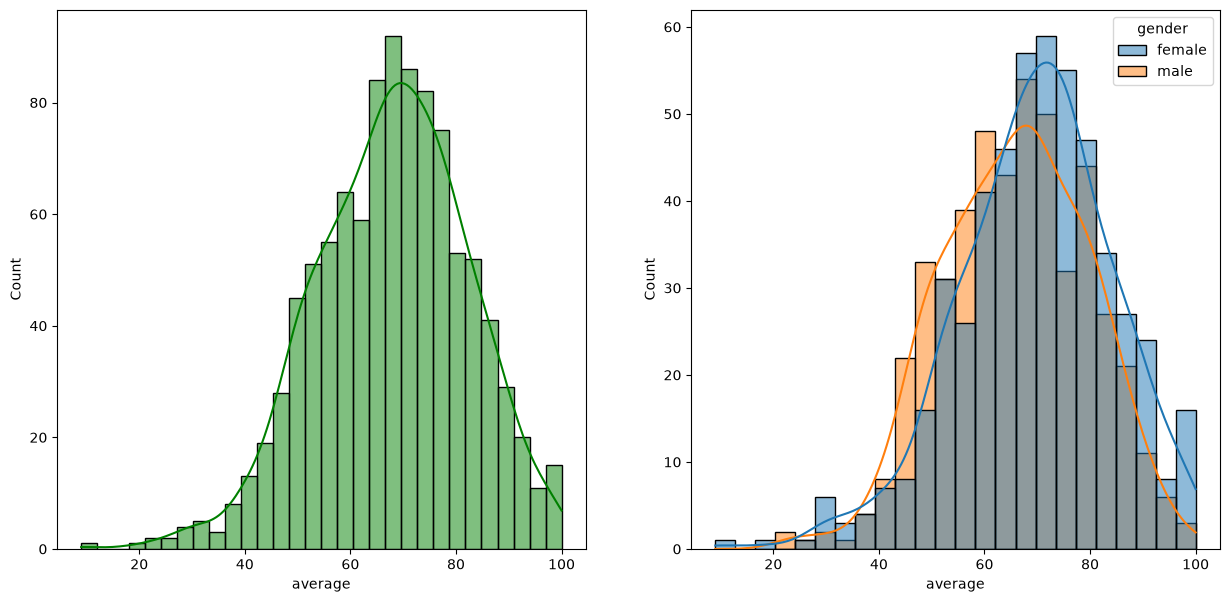

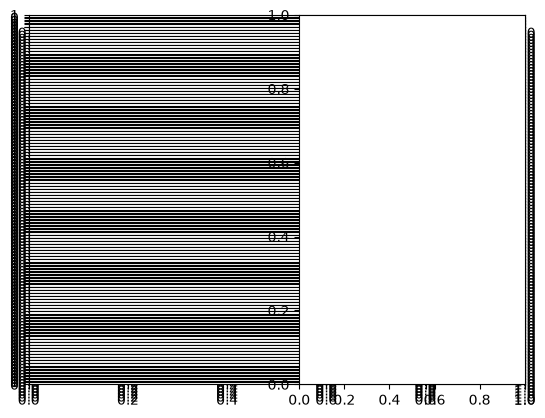

In [52]:
fig, axs = plt.subplots(1,2, figsize=(15,7))
plt.subplots(121)
sns.histplot(data=df,x='average',bins=30,kde=True,color='g',ax=axs[0])
plt.subplot(122)
sns.histplot(data=df,x='average',kde=True,hue='gender',ax=axs[1])
plt.tight_layout()
plt.show()


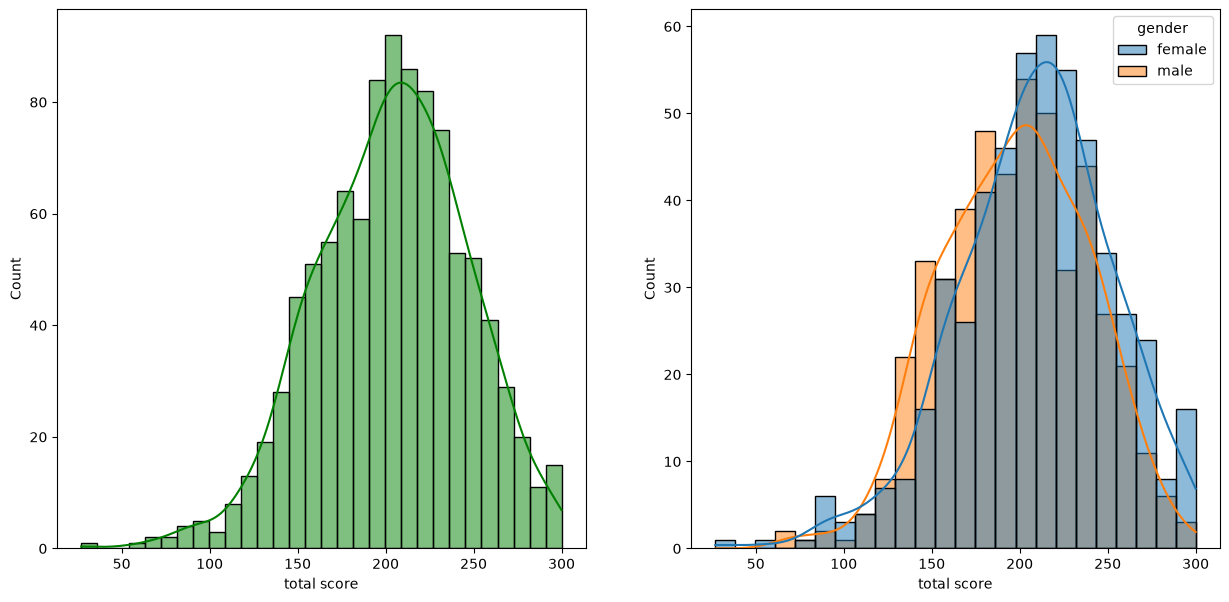

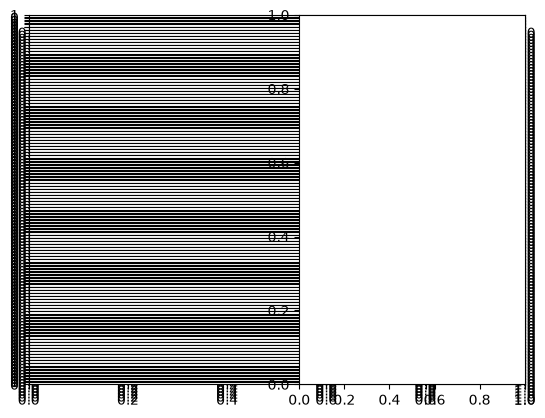

In [56]:
fig, axs = plt.subplots(1,2, figsize=(15,7))
plt.subplots(121)
sns.histplot(data=df,x='total score',bins=30,kde=True,color='g',ax=axs[0])
plt.subplot(122)
sns.histplot(data=df,x='total score',kde=True,hue='gender',ax=axs[1])
plt.tight_layout()
plt.show()

# Insights
* Female students tend to perfomr well than male students

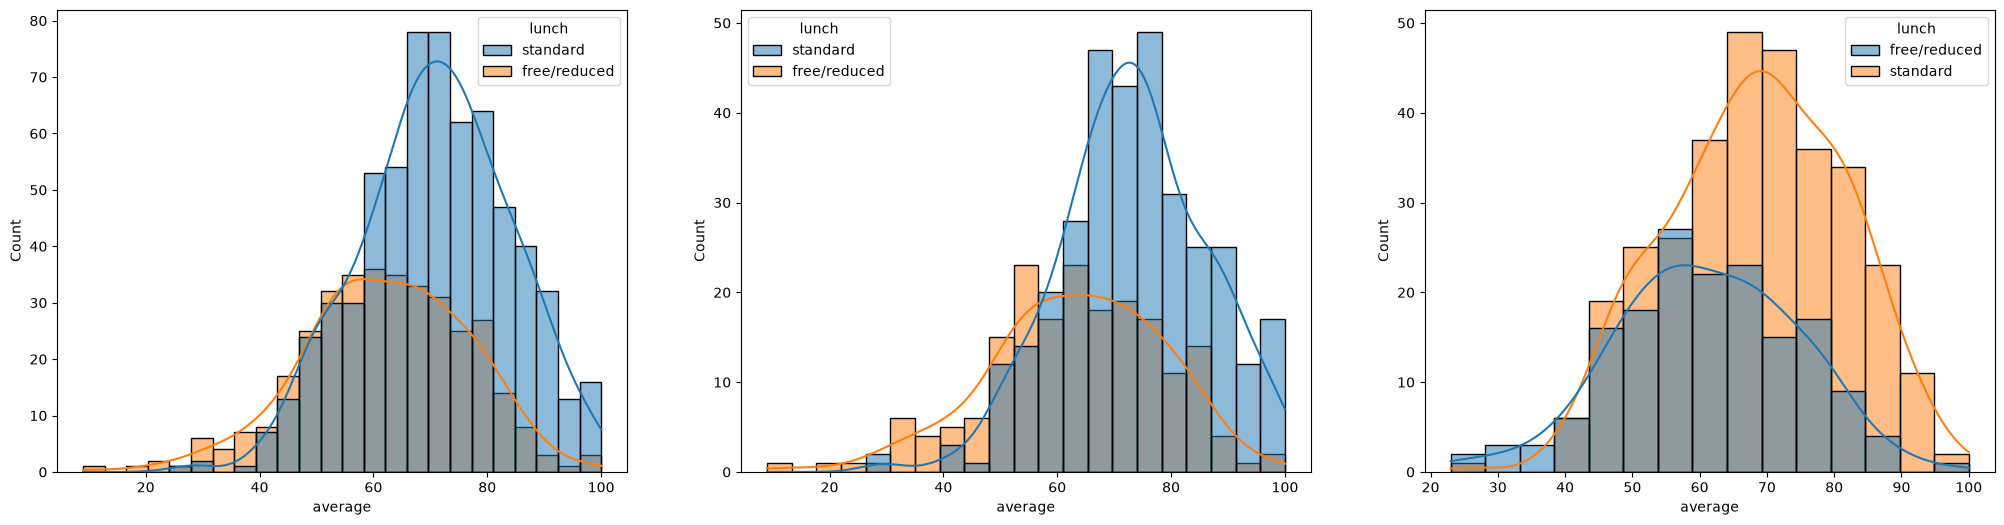

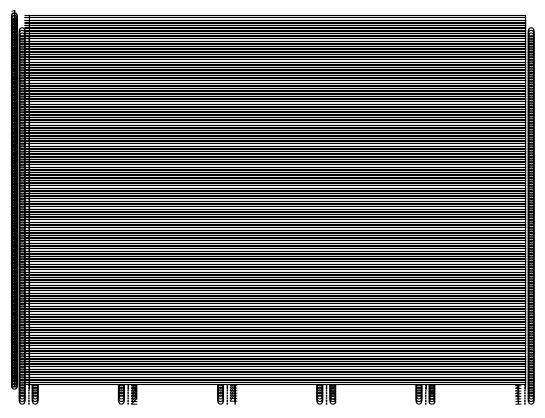

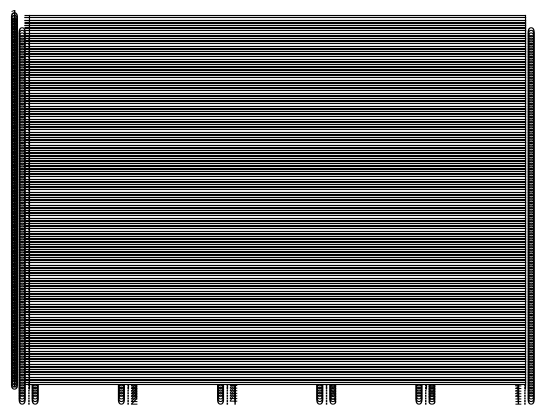

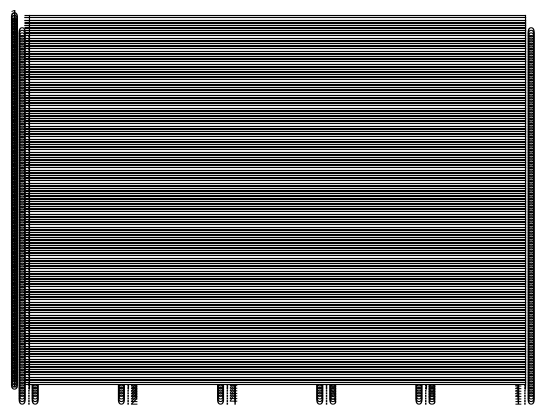

In [ ]:
fig, axs = plt.subplots(1,3, figsize=(25,6))
plt.subplots(141)
sns.histplot(data=df,x='average',kde=True,hue='lunch',ax=axs[0])
plt.subplots(142)
sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='lunch',ax=axs[1])
plt.subplots(143)
sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='lunch',ax=axs[2])
plt.tight_layout()
plt.show()